# Seca e açudes da Paraíba
Previsão mensal de volume armazenado a 3, 4, 5 e 6 meses, em porcentagem da capacidade. Um evento crítico exige volume estritamente inferior a 5%. O snapshot termina em outubro de 2026 e está incluído no projeto. A execução não consulta a internet.

In [1]:
from pathlib import Path
import sys

raiz = Path.cwd()
if not (raiz / 'data/acudes_mensal.csv').exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / 'src'))

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from eda import auditar_medicoes, bloco_contiguo, descrever, plotar_stl
from executar_modelos import executar
from modelos import dados_modelo
from noticias import indices
from avaliar_noticias import ablar, validar

saida = raiz / 'resultados'
saida.mkdir(exist_ok=True)
base, painel = dados_modelo(raiz / 'data')
assert not base.duplicated(['acude_id', 'mes']).any()
display(pd.Series({
    'açudes': painel.shape[1], 'meses': painel.shape[0],
    'leituras válidas': base.volume_pct.notna().sum(),
    'ausências': base.volume_pct.isna().sum(),
    'zeros medidos': base.volume_pct.eq(0).sum(),
    'leituras críticas': base.volume_pct.lt(5).sum(),
}).to_frame('n'))

,n
açudes,131
meses,178
leituras válidas,21577
ausências,1741
zeros medidos,713
leituras críticas,4577


## Dados e análise exploratória
Cada observação conserva a porcentagem publicada pela AESA, inclusive zero e possíveis sangrias acima de 100%. As tabelas sinalizam saltos e divergências da capacidade atual para auditoria. As previsões usam no máximo dois meses de carregamento para o preditor 'último volume'. A ausência de alvo nunca vira uma observação. ADF testa raiz unitária e KPSS testa estacionariedade em nível. Ambos usam o maior bloco contíguo disponível por série.

,sinalizações
acima_capacidade,842
diferenca_capacidade_gt_1pp,0
leitura_mais_15_dias_antes,2807
salto_gt_40pp,173


,acude_id,observacoes,ausentes,mediana_pct,min_pct,max_pct,dp_pp,meses_criticos,bloco_contiguo,ADF_p,KPSS_p_limitado,ACF_nivel_12,ACF_diferenca_12,acude
34,38,174,4,0.070,0.0,18.99,2.889437,165,120,3.643546e-01,0.097270,0.498804,0.597223,Sabonete
0,1,169,9,0.170,0.0,13.41,2.163839,157,129,3.872955e-02,0.100000,0.019144,0.114313,Ouro Velho
48,52,176,2,1.245,0.0,39.35,8.052283,132,163,1.225097e-02,0.100000,0.091043,-0.024625,Riacho de Santo Antônio
77,86,177,1,0.000,0.0,100.65,18.936502,128,133,1.975401e-02,0.100000,-0.041401,0.030032,São José IV
99,110,176,2,1.210,0.0,72.66,16.149541,128,155,9.452491e-10,0.024962,0.300448,0.112223,Várzea Grande
102,117,174,4,1.800,0.0,24.37,5.129593,123,107,1.988163e-02,0.100000,0.180252,0.348736,São Mamede
2,3,167,11,1.580,0.0,104.53,20.252389,121,129,7.159754e-02,0.100000,0.167149,0.084277,Prata II
33,37,175,3,0.330,0.0,29.89,6.898304,119,120,3.537953e-01,0.092287,0.555654,0.387250,Bastiana


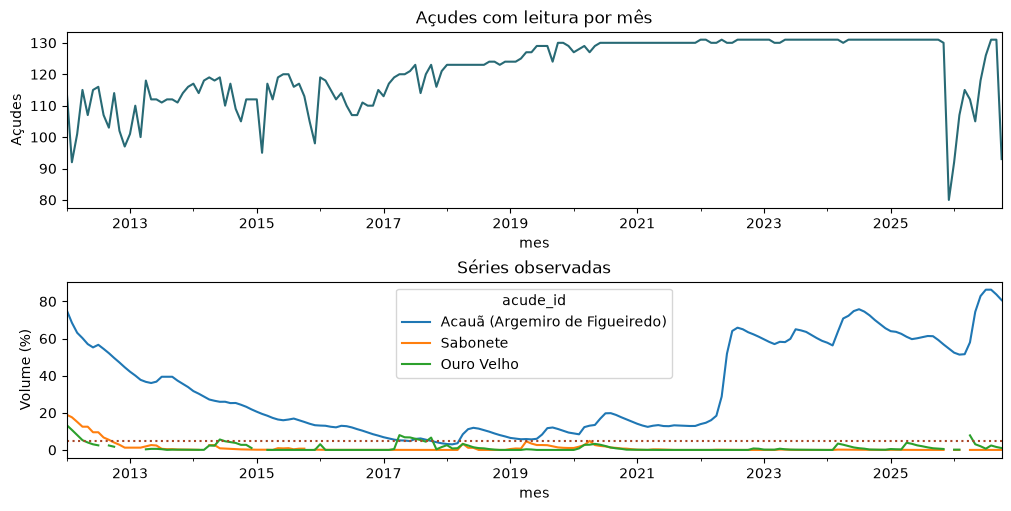

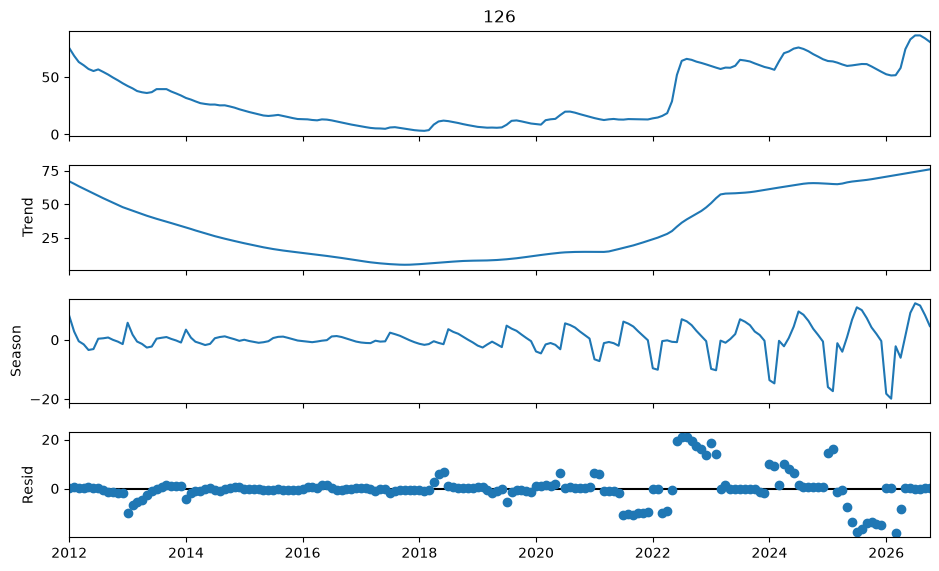

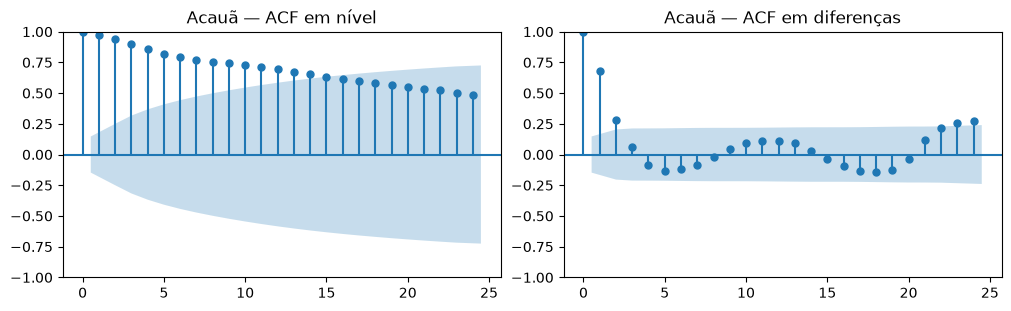

In [2]:
diagnostico = descrever(base, painel)
diagnostico.to_csv(saida / 'diagnostico_acudes.csv', index=False)
qualidade = auditar_medicoes(base)
qualidade.to_csv(saida / 'auditoria_medicoes.csv.gz', index=False)
display(qualidade.iloc[:, -4:].sum().to_frame('sinalizações'))
display(diagnostico.nlargest(8, 'meses_criticos'))

fig, axs = plt.subplots(2, 1, figsize=(10, 5), constrained_layout=True)
painel.notna().sum(axis=1).plot(ax=axs[0], color='#286A75', title='Açudes com leitura por mês')
axs[0].set_ylabel('Açudes')
ids = [126, *[x for x in diagnostico.nlargest(2, 'meses_criticos').acude_id if x != 126]]
nomes = base.set_index('acude_id').acude.to_dict()
painel[ids].rename(columns=nomes).plot(ax=axs[1], title='Séries observadas')
axs[1].axhline(5, color='#aa4728', linestyle=':')
axs[1].set_ylabel('Volume (%)')
plt.show()

figura = plotar_stl(painel[126])
figura.set_size_inches(10, 6)
plt.show()
x = bloco_contiguo(painel[126])
fig, axs = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
plot_acf(x, lags=24, ax=axs[0], title='Acauã — ACF em nível')
plot_acf(x.diff().dropna(), lags=24, ax=axs[1], title='Acauã — ACF em diferenças')
plt.show()

## Seleção e protocolo temporal
Desenvolvimento até dez/2022. A triagem calcula Pearson e Spearman em nível e diferenças nos atrasos 0 a 12. A convenção é x(t−lag) contra y(t). Entre atrasos 1 a 6, escolhe o maior |Spearman| mediano das diferenças por covariável e examina VIF com limiar 10. Granger usa o maior bloco contíguo das diferenças e FDR-BH, como diagnóstico de associação preditiva. O atraso mínimo é um mês para exógenas, com controle adicional de criação do mapa do Monitor.

A coorte exige 60 observações até dez/2022. O walk-forward avança a origem mês a mês. Treino direto usa só alvos conhecidos na origem. A ordenação usa MAE médio dos horizontes na validação até jun/2024. Intervalos por horizonte usam erros de calibração disponíveis até cada origem. A simulação é retrospectiva, com o snapshot final das fontes. A LSTM usa cinco épocas e uma amostra aleatória fixa de até 5.000 exemplos disponíveis a cada origem. Os modelos são referências sazonal e persistência, SARIMAX(1,1,0) com parâmetros ajustados no desenvolvimento e atualização do estado, histogram gradient boosting e LSTM global.

In [3]:
metricas, ranking, futuro, dm = executar(raiz)
display(pd.read_csv(saida / 'atrasos_escolhidos.csv').round(3))
display(pd.read_csv(saida / 'vif.csv').round(3))
display(ranking.round(3).to_frame('MAE validação (p.p.)'))

Atrasos em meses: {'temperatura_c': 6, 'et_fluxo_mj_m2_dia': 1, 'chuva_mm': 2, 'monitor_local_severidade': 6, 'monitor_pb_ge_s0_pct': 6, 'nino34_anom_c': 6}


Origem 2022-12 concluída


Origem 2023-01 concluída


Origem 2023-02 concluída


Origem 2023-03 concluída


Origem 2023-04 concluída


... (39 outputs left out)

Origem 2026-10 concluída


,variavel,lag,median,count,selecionada
0,temperatura_c,6,0.399,130,True
1,et_fluxo_mj_m2_dia,1,0.320,130,True
2,chuva_mm,2,0.243,130,True
3,monitor_local_severidade,6,0.195,130,True
4,monitor_pb_ge_s0_pct,6,0.171,130,True
5,nino34_anom_c,6,0.102,130,True


,rodada,variavel,VIF,removida
0,1,temperatura_c,1.453,False
1,1,et_fluxo_mj_m2_dia,3.512,False
2,1,chuva_mm,3.682,False
3,1,monitor_local_severidade,1.454,False
4,1,monitor_pb_ge_s0_pct,1.467,False
5,1,nino34_anom_c,1.112,False


,MAE validação (p.p.)
modelo,
Gradient boosting,9.150
LSTM,10.817
Sazonal,11.470
Persistência,12.221
SARIMAX,12.410


## Comparação fora do treino
O teste usa alvos de jan/2025 a out/2026 e somente chaves comparáveis. MAPE usa os alvos positivos e sMAPE define 0/0 como zero. MASE usa erro ingênuo sazonal no histórico até cada origem. O Diebold–Mariano usa perda absoluta, média transversal por origem, variância HAC Bartlett, correção de pequena amostra HLN e ajuste de Holm. As 22 origens por horizonte limitam o poder do teste.

,modelo,horizonte,n,MAE_pp,RMSE_pp,n_MAPE,MAPE_pct,sMAPE_pct,MASE,n_MASE,...,FP,FN,VN,precisao,recall,F1,n_intervalos,cobertura_90,largura_90_pp,MAE_macro_pp
0,Gradient boosting,3,2363,7.502,11.817,2299,730.499,37.459,0.622,2363,...,10,152,1948,0.962,0.625,0.757,2363,0.778,31.473,7.576
1,Gradient boosting,4,2370,9.212,13.889,2306,949.493,42.158,0.764,2370,...,8,197,1955,0.963,0.516,0.672,2370,0.738,35.051,9.329
2,Gradient boosting,5,2386,10.030,14.660,2321,834.600,45.505,0.804,2386,...,16,218,1966,0.921,0.460,0.614,2386,0.724,39.511,10.133
3,Gradient boosting,6,2385,11.021,15.839,2321,744.631,48.020,0.874,2385,...,16,223,1964,0.919,0.449,0.604,2385,0.730,42.485,11.178
4,LSTM,3,2363,8.929,14.180,2299,633.309,45.239,0.711,2363,...,66,132,1892,0.805,0.674,0.734,2363,0.858,38.497,9.164
5,LSTM,4,2370,9.824,15.587,2306,674.715,43.136,0.761,2370,...,56,137,1907,0.828,0.663,0.737,2370,0.864,44.392,10.006
6,LSTM,5,2386,10.879,15.871,2321,851.333,49.236,0.852,2386,...,41,239,1941,0.801,0.408,0.541,2386,0.861,45.963,11.016
7,LSTM,6,2385,11.857,17.696,2321,528.551,51.729,0.893,2385,...,61,183,1919,0.784,0.548,0.645,2385,0.855,49.008,11.980
8,Persistência,3,2363,8.172,14.257,2299,43.629,31.821,0.582,2363,...,45,53,1913,0.887,0.869,0.878,2363,0.926,45.005,8.200
9,Persistência,4,2370,9.852,16.486,2306,58.561,38.518,0.702,2370,...,58,69,1905,0.854,0.830,0.842,2370,0.920,52.216,9.904


,horizonte,origens,modelo_a,modelo_b,dif_perda_pp,DM_HLN,p,p_holm
0,3,22,Gradient boosting,LSTM,-1.417,-2.775,0.011,0.045
1,4,22,Gradient boosting,LSTM,-0.728,-0.801,0.432,0.821
2,5,22,Gradient boosting,LSTM,-0.882,-1.471,0.156,0.468
3,6,22,Gradient boosting,LSTM,-1.023,-0.840,0.410,0.821


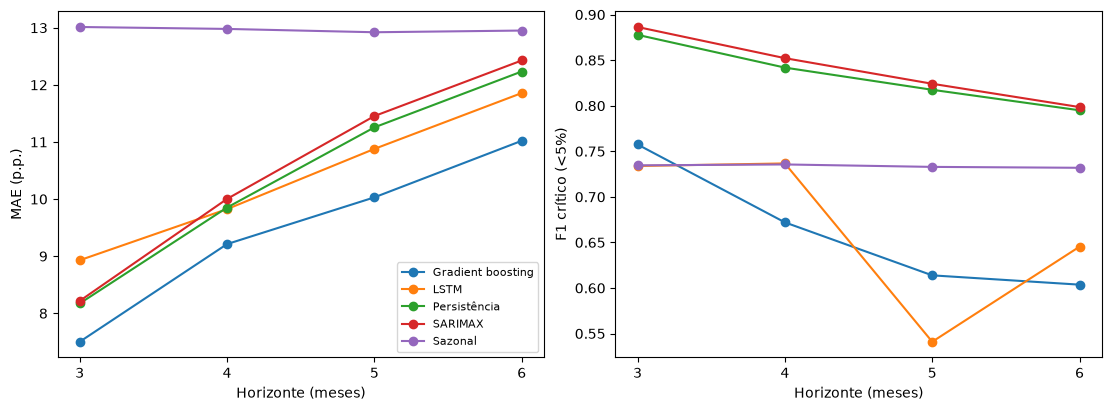

In [4]:
display(metricas.round(3))
display(dm.round(3))
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for nome, grupo in metricas.groupby('modelo'):
    axs[0].plot(grupo.horizonte, grupo.MAE_pp, marker='o', label=nome)
    axs[1].plot(grupo.horizonte, grupo.F1, marker='o')
axs[0].set_ylabel('MAE (p.p.)')
axs[1].set_ylabel('F1 crítico (<5%)')
for ax in axs:
    ax.set_xlabel('Horizonte (meses)')
    ax.set_xticks([3, 4, 5, 6])
axs[0].legend(fontsize=8)
plt.show()

## Projeções e alertas
O modelo escolhido na validação projeta de jan/2027 a abr/2027 com origem em out/2026. As 131 estações aparecem no arquivo, com marcação de exclusões da coorte e de valores ausentes. Um intervalo que cruza o limiar indica incerteza sobre o alerta pontual.

In [5]:
alertas = futuro.loc[futuro.critico_pontual.fillna(False)]
display(futuro.groupby('mes_alvo').agg(
    com_previsao=('previsto', 'count'), alertas=('critico_pontual', 'sum'),
    intervalos_cruzam_5=('intervalo_cruza_5', 'sum')
))
display(alertas[['acude','mes_alvo','previsto','inferior_90','superior_90','ultima_leitura']]
        .sort_values(['mes_alvo','previsto']).head(30).round(2))

,com_previsao,alertas,intervalos_cruzam_5
mes_alvo,,,
2027-01,123,23,38
2027-02,123,22,36
2027-03,123,4,23
2027-04,123,2,25


,acude,mes_alvo,previsto,inferior_90,superior_90,ultima_leitura
8,Prata II,2027-01,0.00,0.0,23.45,2026-10-14
12,Bichinho,2027-01,0.00,0.0,23.45,2026-10-14
132,Bastiana,2027-01,0.00,0.0,23.45,2026-10-20
192,Riacho de Santo Antônio,2027-01,0.00,0.0,23.45,2026-10-09
304,Jeremias,2027-01,0.00,0.0,23.45,2026-10-31
308,São José IV,2027-01,0.00,0.0,23.45,2026-10-31
312,São José III,2027-01,0.00,0.0,23.45,2026-10-14
344,Curimataú,2027-01,0.00,0.0,23.45,2026-10-14
392,Caraibeiras,2027-01,0.00,0.0,23.45,2026-10-14
396,Várzea Grande,2027-01,0.00,0.0,23.45,2026-10-31


## Índice de notícias e validação
O índice mensal é a proporção de comunicados AESA classificados na classe 2 pelo Qwen2.5-1.5B-Instruct quantizado. Uma regra lexical fixa serve de comparação. O experimento usa o índice do mês anterior para corrigir resíduos do modelo vencedor, com a mesma amostra para os métodos. O resultado é exploratório enquanto a auditoria de rótulos humanos indicar menos de 200 pares válidos e adjudicados.

In [6]:
import json
pasta_noticias = raiz / 'data/noticias'
classificacoes = pd.read_csv(pasta_noticias / 'classificacao_automatica.csv')
indices(classificacoes).to_csv(pasta_noticias / 'indice_mensal.csv')
pares = pd.read_csv(saida / 'previsoes_walk_forward.csv.gz')
for campo in ['origem', 'mes_alvo']:
    pares[campo] = pd.PeriodIndex(pares[campo], freq='M')
ablar(pares, ranking.index[0], pasta_noticias / 'indice_mensal.csv', saida)
validar(pasta_noticias, saida)
status_noticias = saida / 'validacao_noticias.json'
if status_noticias.exists():
    display(json.loads(status_noticias.read_text(encoding='utf-8')))
ablacao = saida / 'ablacao_noticias.csv'
if ablacao.exists():
    display(pd.read_csv(ablacao).round(3))

{'pares_humanos_validos': 0,
 'minimo': 200,
 'validacao_humana_concluida': False}

,versao,horizonte,MAE_pp,n,origens,RMSE_pp,modelo_base
0,com_lexical,3,8.623,2483,22,13.394,Gradient boosting
1,com_lexical,4,10.772,2479,22,15.680,Gradient boosting
2,com_lexical,5,12.235,2473,22,16.727,Gradient boosting
3,com_lexical,6,13.404,2472,22,18.025,Gradient boosting
4,com_llm,3,8.464,2483,22,13.366,Gradient boosting
5,com_llm,4,10.496,2479,22,15.570,Gradient boosting
6,com_llm,5,11.839,2473,22,16.580,Gradient boosting
7,com_llm,6,13.007,2472,22,17.893,Gradient boosting
8,previsto,3,7.957,2483,22,13.037,Gradient boosting
9,previsto,4,9.657,2479,22,14.969,Gradient boosting
